# Phase 2: Baseline Model Training & Comparative Evaluation
## Configuration: 2-Tier Binary CAD Detection (Healthy vs. CAD Present)
### Evaluated Architectures: Logistic Regression, KNN, SVM, Random Forest, Lightweight Neural Network

### Clinical & Methodological Scope:
Binary CAD detection (Tier 0: Healthy [<50% stenosis] vs. Tier 1: CAD Present [>=50% stenosis]).

### Baseline Architecture Portfolio:
1. **Multinomial / Binary Logistic Regression**: Standard linear probability baseline.
2. **K-Nearest Neighbors (KNN)**: Non-parametric distance-based instance classifier ($k=5$).
3. **Support Vector Classifier (SVM)**: Maximum-margin hyperplane with non-linear RBF kernel.
4. **Random Forest Classifier**: Ensemble of 100 decorrelated decision trees.
5. **Lightweight Neural Network (MLP)**: Feedforward architecture (64 -> 32 neurons) with early stopping.

### Zero-Leakage Guarantee:
All models are trained exclusively on `X_train` (242 samples) and evaluated on the completely untouched holdout test split ($N=61$).

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve, auc
)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("[OK] Baseline modeling environment and specialized architectures loaded successfully.")

[OK] Baseline modeling environment and specialized architectures loaded successfully.


In [2]:
candidates = [
    os.path.join('..', 'datasets', 'heart+disease', 'processed.cleveland.data'),
    os.path.join('datasets', 'heart+disease', 'processed.cleveland.data'),
    'processed.cleveland.data'
]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Could not locate 'processed.cleveland.data'.")

COLUMNS = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

df_raw = pd.read_csv(data_path, names=COLUMNS, na_values='?')

df_raw['target_processed'] = (df_raw['target'] > 0).astype(int)
class_names = ['Tier 0 (Healthy)', 'Tier 1 (CAD Present)']
classes_list = [0, 1]

# Train-Test Split
X = df_raw.drop(columns=['target', 'target_processed']).copy()
y = df_raw['target_processed'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Imputation fit strictly on X_train
ca_median = X_train['ca'].median()
thal_mode = X_train['thal'].mode()[0]
X_train['ca'] = X_train['ca'].fillna(ca_median)
X_test['ca'] = X_test['ca'].fillna(ca_median)
X_train['thal'] = X_train['thal'].fillna(thal_mode)
X_test['thal'] = X_test['thal'].fillna(thal_mode)

# One-Hot Encoding
nominal_cols = ['cp', 'restecg', 'slope', 'thal']
X_train_ohe = pd.get_dummies(X_train, columns=nominal_cols, drop_first=False)
X_test_ohe = pd.get_dummies(X_test, columns=nominal_cols, drop_first=False)
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)

# MinMax Scaling
cont_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
scaler = MinMaxScaler()
X_train_scaled = X_train_ohe.copy()
X_test_scaled = X_test_ohe.copy()
X_train_scaled[cont_cols] = scaler.fit_transform(X_train_ohe[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test_ohe[cont_cols])

X_train_final, y_train_final = X_train_scaled, y_train
print(f"[OK] Training fold prepared authentically: {len(y_train_final)} instances.")

print(f"[OK] Holdout test set: {len(y_test)} instances.")

[OK] Training fold prepared authentically: 242 instances.
[OK] Holdout test set: 61 instances.


### 1. Training the 5 Baseline Architectures
We initialize and train all five candidate architectures using default configurations.

In [3]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Neural Network (LNN)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train_final, y_train_final)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred) # Sensitivity
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    spec = tn / (tn + fp)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Sensitivity (Recall)': rec,
        'Specificity': spec,
        'F1-Score': f1,
        'ROC-AUC': auc_score
    })

df_results = pd.DataFrame(results)
print("=== BASELINE EVALUATION RESULTS (2-TIER BINARY) ===")
print(df_results.to_string(index=False))

=== BASELINE EVALUATION RESULTS (2-TIER BINARY) ===
                 Model  Accuracy  Precision  Sensitivity (Recall)  Specificity  F1-Score  ROC-AUC
   Logistic Regression  0.885246   0.838710              0.928571     0.848485  0.881356 0.952381
   K-Nearest Neighbors  0.868852   0.812500              0.928571     0.818182  0.866667 0.916126
Support Vector Machine  0.868852   0.857143              0.857143     0.878788  0.857143 0.941558
         Random Forest  0.868852   0.833333              0.892857     0.848485  0.862069 0.931277
  Neural Network (LNN)  0.819672   0.774194              0.857143     0.787879  0.813559 0.911255


### 2. Detailed Per-Model Classification Reports

In [4]:
for name, pred in predictions.items():
    print(f"\n=======================================================")
    print(f"CLASSIFICATION REPORT: {name}")
    print(f"=======================================================")
    print(classification_report(y_test, pred, target_names=class_names, zero_division=0))


CLASSIFICATION REPORT: Logistic Regression
                      precision    recall  f1-score   support

    Tier 0 (Healthy)       0.93      0.85      0.89        33
Tier 1 (CAD Present)       0.84      0.93      0.88        28

            accuracy                           0.89        61
           macro avg       0.89      0.89      0.89        61
        weighted avg       0.89      0.89      0.89        61


CLASSIFICATION REPORT: K-Nearest Neighbors
                      precision    recall  f1-score   support

    Tier 0 (Healthy)       0.93      0.82      0.87        33
Tier 1 (CAD Present)       0.81      0.93      0.87        28

            accuracy                           0.87        61
           macro avg       0.87      0.87      0.87        61
        weighted avg       0.88      0.87      0.87        61


CLASSIFICATION REPORT: Support Vector Machine
                      precision    recall  f1-score   support

    Tier 0 (Healthy)       0.88      0.88      0.88 

### 3. Visual Diagnostic Suite: Confusion Matrices & ROC Curves

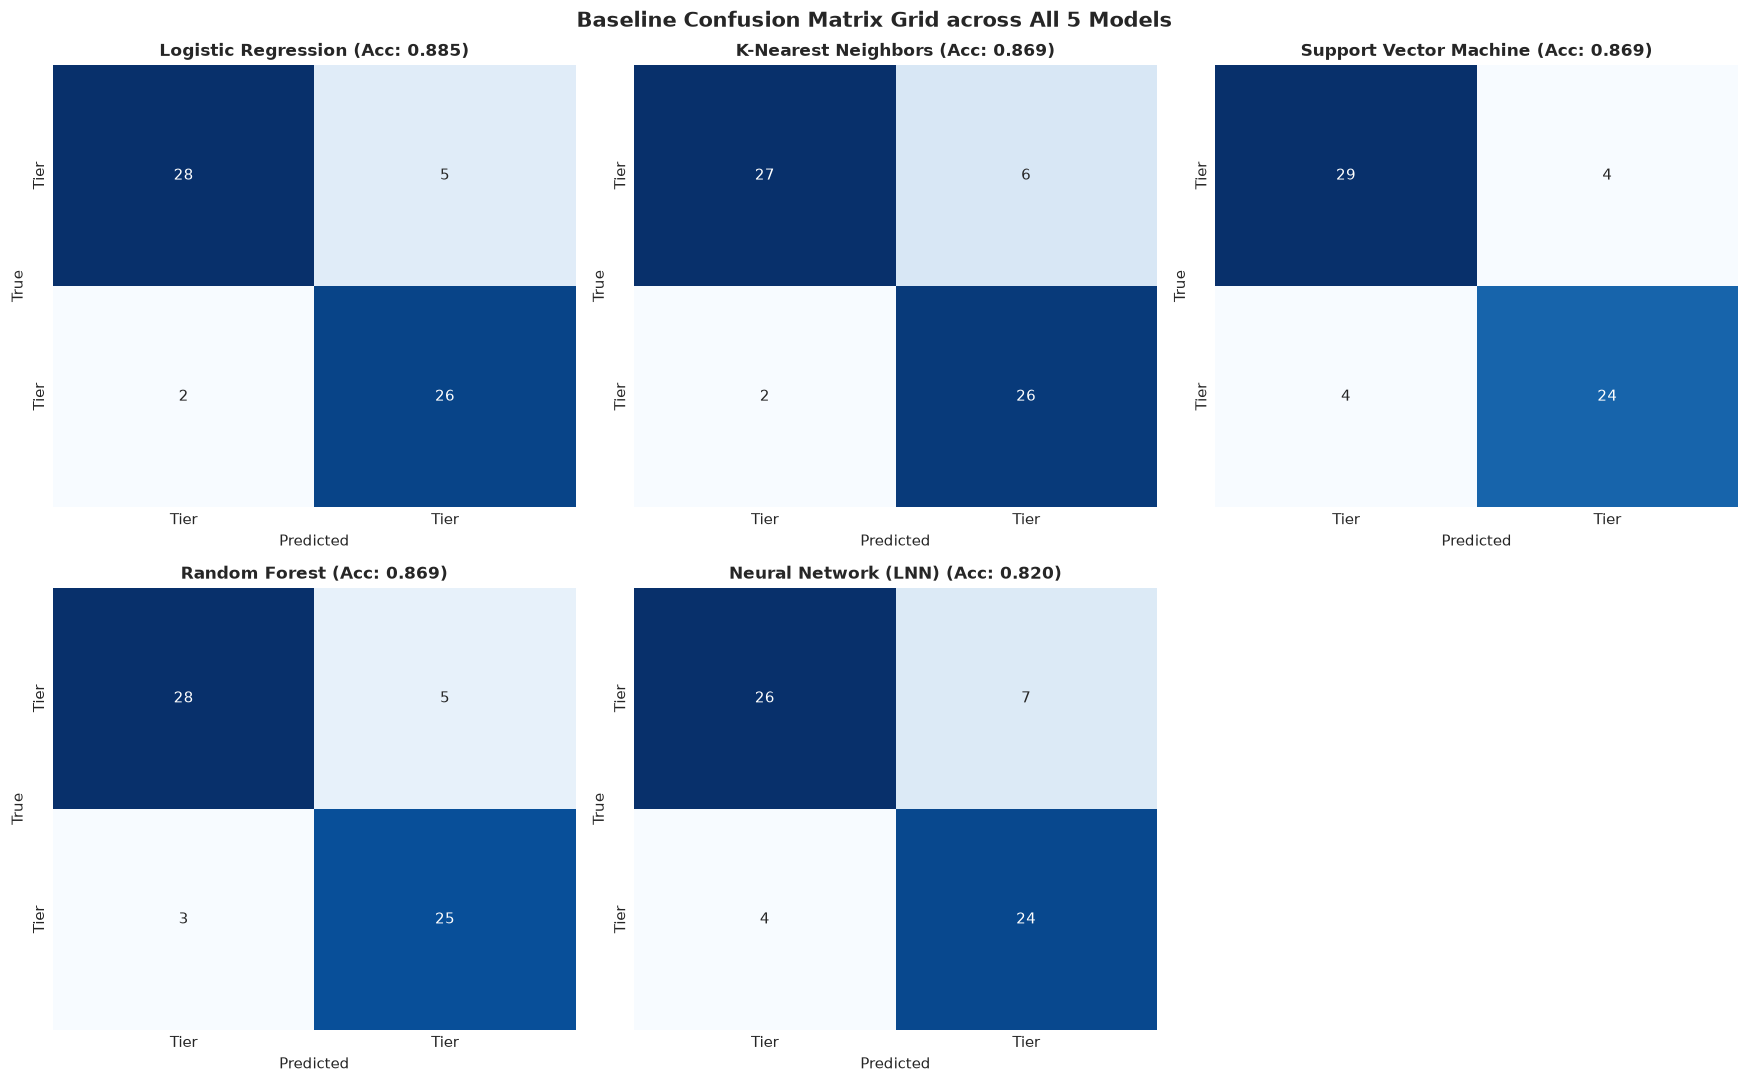

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=[c.split(' ')[0] for c in class_names],
                yticklabels=[c.split(' ')[0] for c in class_names])
    acc_val = df_results.loc[df_results['Model'] == name, 'Accuracy'].values[0]
    axes[idx].set_title(f'{name} (Acc: {acc_val:.3f})', fontweight='bold', fontsize=11)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('True')

# Hide 6th empty subplot
axes[5].axis('off')

plt.suptitle('Baseline Confusion Matrix Grid across All 5 Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

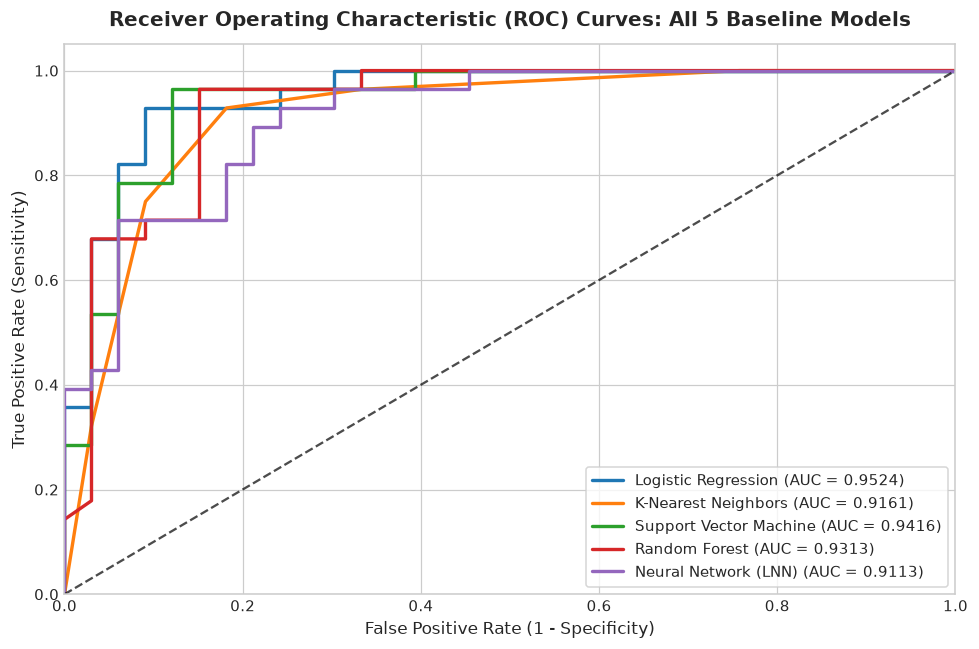

In [6]:
plt.figure(figsize=(9, 6))

for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2.2, label=f'{name} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC) Curves: All 5 Baseline Models', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

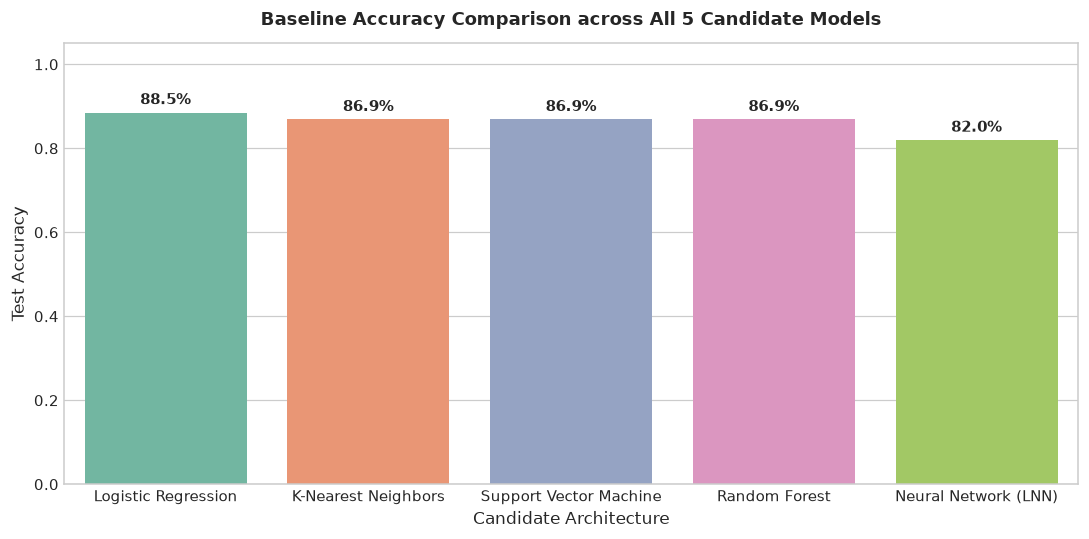

In [7]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='Accuracy', data=df_results, palette='Set2')
plt.title('Baseline Accuracy Comparison across All 5 Candidate Models', fontsize=12, fontweight='bold', pad=12)
plt.ylim(0, 1.05)
plt.ylabel('Test Accuracy', fontsize=11)
plt.xlabel('Candidate Architecture', fontsize=11)
for idx, row in df_results.iterrows():
    plt.text(idx, row['Accuracy'] + 0.02, f"{row['Accuracy']*100:.1f}%", ha='center', fontweight='bold', fontsize=9.5)
plt.tight_layout()
plt.show()

### 4. Baseline Modeling Insights & Transition to Phase 3
- The baseline models establish the initial performance floor.
- In `hyperparameter_tuning.ipynb`, we systematically optimize all 5 models via 5-fold cross-validation across comprehensive hyperparameter search spaces.